### Early Detection of Event-Associated Consumer Interest Shifts

**COMP8851 Major Project — Group 3**.

---
### Step — Install and import

In [51]:
import re
import time
import warnings
from datetime import timedelta
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
from pytrends.request import TrendReq

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [52]:
DF = "Olympics_Tokyo_tweets.csv"
FDATE = pd.Timestamp("2021-07-28")    
JHOURS = 9                              
SKIP_DAY = "2021-07-25"                      
MIN_WORDS = 4                               
MIN_TOPIC_SIZE = 50  
                       
print("Focal event date:", FOCAL_DATE.date())

Focal event date: 2021-07-28


---
### Step — Look at the data

In [53]:
tweets = pd.read_csv(DF, low_memory=False)

print("Tweets in the file:", len(tweets))
print("Columns:", list(tweets.columns))
print()
print("The three columns we actually use:")
print("text - what the person wrote")
print("date - when they wrote it")
print("user_screen_name - who wrote it (we only use this to count accounts)")

Tweets in the file: 312825
Columns: ['id', 'text', 'user_screen_name', 'user_location', 'retweet_count', 'favorited', 'favorite_count', 'user_description', 'user_created_at', 'user_followers', 'user_friends', 'date', 'language']

The three columns we actually use:
text - what the person wrote
date - when they wrote it
user_screen_name - who wrote it (we only use this to count accounts)


In [54]:
# Convert the date column and change it to Japan time
tweets["time"] = pd.to_datetime(tweets["date"], errors="coerce")
tweets = tweets.dropna(subset=["time"]) # dropping rows with a broken date

tweets["time"] = tweets["time"] + pd.Timedelta(hours=JHOURS)
tweets["day"] = tweets["time"].dt.date

print("Tweets we can use:", len(tweets))
print()
print("Tweets on each day:")
print(tweets.groupby("day").size().to_string())

Tweets we can use: 312791

Tweets on each day:
day
2021-07-25      500
2021-07-26    47000
2021-07-27    62499
2021-07-28    32499
2021-07-29    30000
2021-07-30    32497
2021-07-31    51415
2021-08-01    33885
2021-08-08    22496


The collection is not continuous. Some days have tens of thousands of
tweets and some have very few. There is also a gap in early August where nothing was collected.

---
### Step — Keeping only gymnastics tweets

We search every tweet for gymnastics words and keep the ones that match for first experiment.

Our research question is about one specific event. The file contains
tweets about swimming, basketball, politics and everything else. If we left those in, the topic
model would mostly find topics about other sports and we would never see the gymnastics
discussion clearly.

Also, we only use *competition* words in the filter — never consumer words
like "buy" or "leotard". If we put "leotard" in the filter we would obviously find a topic about
leotards, but we would have put it there ourselves. That would make our answer to RQ2
meaningless.

In [55]:
# Only gymnastics and competition words. No shopping words.
gym_words = [
    "gymnast", "gymnastics", "artistic gymnastics",
    "all-around", "all around", "allaround",
    "pommel", "vault", "rings", "parallel bars", "high bar",
    "floor exercise", "apparatus", "routine", "dismount",
    "hashimoto", "xiao ruoteng", "nikita nagornyy",
    "sunisa lee", "simone biles", "carlos yulo",
]

print("Searching", len(gym_words), "words")

Searching 21 words


In [56]:
def clean_for_scope(t):
    t = str(t)
    t = re.sub(r"http\S+", " ", t)
    t = re.sub(r"@\w+", " ", t)
    t = t.replace("#", "")
    t = re.sub(r"[^A-Za-z ]+", " ", t)
    return re.sub(r"\s+", " ", t).strip().lower()

text = tweets["text"].astype(str).str.lower() # Finding tweets containing any gymnastics word

is_gymnastics = pd.Series(False, index=tweets.index)
for word in gym_words:
    is_gymnastics = is_gymnastics | text.str.contains(word, regex=False, na=False)

gym_tweets = tweets[is_gymnastics].copy()

print("Gymnastics tweets:", len(gym_tweets))
print("That is", round(100 * len(gym_tweets) / len(tweets), 2), "% of all tweets")
print("Gymnastics tweets per day:")
print(gym_tweets.groupby("day").size().to_string())

Gymnastics tweets: 11670
That is 3.73 % of all tweets
Gymnastics tweets per day:
day
2021-07-25       5
2021-07-26    1238
2021-07-27    2235
2021-07-28    2626
2021-07-29    1036
2021-07-30    1171
2021-07-31    1510
2021-08-01     927
2021-08-08     922


#### Why we remove 25 July

Look at the numbers above. 25 July has only 5 gymnastics tweets.

The reason of removing 25th July is that later when we compare each day with the day before it. With 5
tweets, almost every topic has a score of zero on 25 July — simply because there are not enough
tweets for anything to appear. Then on 26 July, when we have over a thousand tweets, every
topic jumps up from zero.

In [57]:
before = len(gym_tweets)
gym_tweets = gym_tweets[gym_tweets["day"] != pd.Timestamp(SKIP_DAY).date()]

print("Removed", SKIP_DAY, "-", before - len(gym_tweets), "tweets")
print("Gymnastics tweets left:", len(gym_tweets))
print()

print("Using in the experiment days:")
for day in sorted(gym_tweets["day"].unique()):
    n = (gym_tweets["day"] == day).sum()
    if day < FDATE.date():
        when = "Before"
    elif day == FDATE.date():
        when = "Focal Day"
    else:
        when = "After"
    print(f"   {day}   {n:>5} tweets   {when}")

Removed 2021-07-25 - 5 tweets
Gymnastics tweets left: 11665

Using in the experiment days:
   2021-07-26    1238 tweets   Before
   2021-07-27    2235 tweets   Before
   2021-07-28    2626 tweets   Focal Day
   2021-07-29    1036 tweets   After
   2021-07-30    1171 tweets   After
   2021-07-31    1510 tweets   After
   2021-08-01     927 tweets   After
   2021-08-08     922 tweets   After


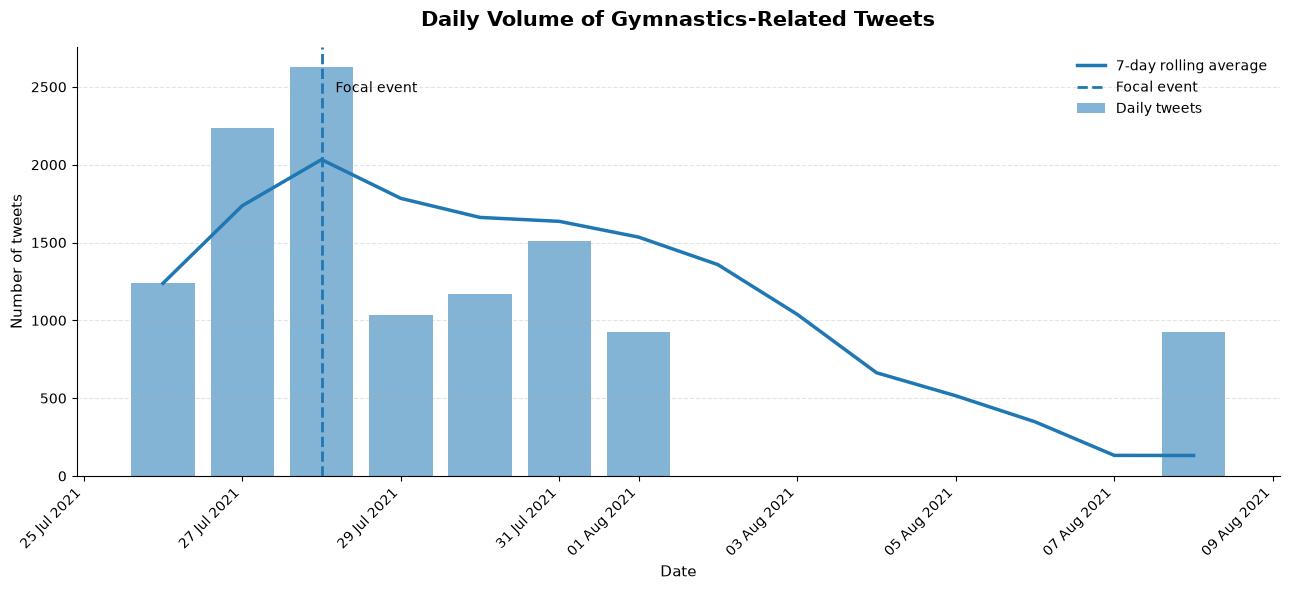

In [ ]:
gym_tweets["day"] = pd.to_datetime(gym_tweets["day"])

# Counting tweets per calendar day
daily_counts = (
    gym_tweets
    .groupby("day")
    .size()
    .rename("tweet_count")
)

# Creating a complete calendar-day index
full_dates = pd.date_range(
    start=daily_counts.index.min(),
    end=daily_counts.index.max(),
    freq="D"
)

daily_counts = daily_counts.reindex(
    full_dates,
    fill_value=0
)

# Calculating 7-calendar-day rolling average
rolling_avg = daily_counts.rolling(
    window=7,
    min_periods=1
).mean()

fig, ax = plt.subplots(figsize=(13, 6))

# Daily tweets
ax.bar(
    daily_counts.index,
    daily_counts.values,
    width=0.8,
    alpha=0.55,
    label="Daily tweets"
)

# 7-day rolling average
ax.plot(
    daily_counts.index,
    rolling_avg,
    linewidth=2.5,
    label="7-day rolling average"
)

# Focal event
focal_date = pd.to_datetime(FDATE)

ax.axvline(
    focal_date,
    linestyle="--",
    linewidth=2,
    label="Focal event"
)

# Event annotation
ax.annotate(
    "Focal event",
    xy=(focal_date, daily_counts.max()),
    xytext=(10, -10),
    textcoords="offset points",
    ha="left",
    va="top",
    fontsize=10
)

# Labels
ax.set_title(
    "Daily Volume of Gymnastics-Related Tweets",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Date", fontsize=11)
ax.set_ylabel("Number of tweets", fontsize=11)

# Diagonal dates
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b %Y")
)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right"
)

# Grid
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

# Remove top/right borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False)

plt.tight_layout()
plt.show()

---
### Step  — The reason of choosing gymnastics tweets for first experiment

So we run BERTopic on
the **whole** dataset — every sport, not just gymnastics — and look at what it finds.

If gymnastics topics come out clearly in the whole dataset, we do
not need the filter. If they get swallowed by bigger sports, we do.

We used a random sample of 60,000 tweets for experiment.

In [59]:
# Preparing the whole dataset the same way we prepare the gymnastics one
whole = tweets.drop_duplicates(subset="id").copy()
whole = whole[whole["text"].notna()]
whole = whole[~whole["text"].astype(str).str.startswith("RT @")]
whole = whole.drop_duplicates(subset="text")
whole["clean"] = whole["text"].apply(clean_for_scope)
whole = whole[whole["clean"].str.split().str.len() >= MIN_WORDS]
print("Whole dataset after cleaning:", len(whole), "tweets")
sample = whole.sample(min(60000, len(whole)), random_state=42).reset_index(drop=True)
print("Sample for experiment:", len(sample), "tweets")

Whole dataset after cleaning: 291402 tweets
Sample for experiment: 60000 tweets


In [ ]:
# Runing BERTopic on the whole dataset (not just gymnastics)
try:
    from sentence_transformers import SentenceTransformer
    scope_embedder = SentenceTransformer("all-MiniLM-L6-v2")
    scope_vectors = scope_embedder.encode(sample["clean"].tolist(), show_progress_bar=False)
except Exception:
    from sklearn.pipeline import make_pipeline
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.decomposition import TruncatedSVD
    scope_embedder = make_pipeline(
        TfidfVectorizer(min_df=10, stop_words="english", max_features=20000),
        TruncatedSVD(80, random_state=42))
    scope_vectors = scope_embedder.fit_transform(sample["clean"].tolist())

scope_model = BERTopic(
    umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
                    metric="cosine", random_state=42, low_memory=True),
    hdbscan_model=HDBSCAN(min_cluster_size=120, metric="euclidean"),
    verbose=False)

scope_labels, _ = scope_model.fit_transform(sample["clean"].tolist(), scope_vectors)
sample["topic"] = scope_labels

scope_words = {}
for t in scope_model.get_topic_info()["Topic"]:
    if t != -1:
        scope_words[t] = ", ".join(w for w, s in scope_model.get_topic(t)[:8])

print()
print("Topics found in the whole dataset:", len(scope_words))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Running BERTopic on the whole dataset. This takes a few minutes.

Topics found in the whole dataset: 75


In [61]:
sizes = sample["topic"].value_counts() # What are the biggest topics?

print("The 20 Biggest topics in the whole dataset")
shown = 0
for t in sizes.index:
    if t == -1:
        continue
    print(f"{sizes[t]:>6} tweets  |  {scope_words[t][:72]}")
    shown += 1
    if shown == 20:
        break

The 20 Biggest topics in the whole dataset
  5284 tweets  |  olympics, the, watching, it, this, to, watch, are
  2820 tweets  |  tokyo, japan, tokyoolympics, olympics, japanese, the, of, day
  1774 tweets  |  she, her, was, to, is, the, and, in
  1438 tweets  |  coverage, bbc, nbc, tv, watch, on, live, the
  1353 tweets  |  india, neeraj, chopra, cricket, indian, neerajchopra, javelin, gold
  1282 tweets  |  you, your, this, proud, it, so, we, are
  1183 tweets  |  gold, medal, medals, you, proud, silver, gb, we
  1131 tweets  |  badminton, sindhu, pv, pvsindhu, yamaguchi, tai, game, match
  1048 tweets  |  he, his, him, was, olympics, the, man, is
  1019 tweets  |  women, men, female, girls, are, soccer, the, transgender
   944 tweets  |  played, songs, song, playing, music, fever, dj, exo
   799 tweets  |  covid, cases, positive, pandemic, coronavirus, tokyo, vaccine, virus
   788 tweets  |  boxing, boxer, lovlina, borgohain, pooja, round, rani, india
   728 tweets  |  biles, simone,

Based on the results some of the biggest topics are just common words like *olympics, the, is,
at* — that happens because so many tweets share only general Olympic words. The real topics are
split by **sport** (hockey, tennis, badminton, basketball) and by **country** (India, USA,
Japan).

Now let us count how much of it is gymnastics.

In [62]:
gym_check = ["gymnast", "gymnastics", "all-around", "allaround", "pommel",
             "vault", "biles", "sunisa", "hashimoto"]

def mentions_any(text, words):
    for w in words:
        if re.search(r"\b" + w + r"\b", text):
            return True
    return False

gym_topics_found = [] # How many topics are about gymnastics?
for t in scope_words:
    if mentions_any(scope_words[t].lower(), gym_check):
        gym_topics_found.append(t)

share = sample["clean"].apply(lambda s: mentions_any(s, gym_check)).mean() # How many tweets mention gymnastics at all?

print(f"   Tweets mentioning gymnastics : {share:.1%} of the whole dataset (60000 sample)")
print(f"   Topics about gymnastics      : {len(gym_topics_found)} out of {len(scope_words)}")
print("The gymnastics topics we found:")
for t in gym_topics_found:
    print(f"   {sizes.get(t, 0):>5} tweets  |  {scope_words[t][:68]}")

   Tweets mentioning gymnastics : 3.0% of the whole dataset (60000 sample)
   Topics about gymnastics      : 3 out of 75
The gymnastics topics we found:
     728 tweets  |  biles, simone, around, withdraws, gymnastics, from, her, mental
     386 tweets  |  gymnastics, gymnast, gymnasts, rhythmic, men, team, women, the
     323 tweets  |  horse, horses, equestrian, dressage, dancing, dance, pommel, the


### Findings

Gymnastics is only about 3% of the dataset, and it gets only a few topics out
of over a hundred. The gymnastics topics we do get are dominated by the biggest story of the
Games (Simone Biles withdrawing) — the smaller consumer stories are not there at all.

BERTopic groups tweets that are close together. A consumer topic with a few
hundred tweets is simply too small to form its own group inside a dataset of 291,000. It gets
swallowed into a bigger topic or thrown into the outliers.

Keeping only gymnastics tweets takes those few hundred tweets from being a tiny
fraction of the data to being a noticeable part of it. That is what lets BERTopic find them.

The whole-dataset run also found consumer topics that are about
the Olympics generally, not gymnastics. Those are real consumer interests, but they are outside
what our project is about, and our filter removes them. We say this in our limitations rather
than pretending it does not happen.

---
### Step — Cleaning the text

We removing links, @mentions, emoji and punctuation.

BERTopic groups tweets by the words in them. A link like
`https://t.co/x7Kd` is not a word — it is random letters. If we leave links in, the model may
group tweets simply because they both contain a link, which tells us nothing.

Also, we deleted the `#` symbol but keep the word after it, so
`#gymnastics` becomes `gymnastics`. This is deliberate: hashtags carry real meaning, and
treating `#gymnastics` and `gymnastics` as two different words would split the same topic in
two.

In [63]:
def clean(t):
    """Clean one tweet."""
    t = str(t)
    t = re.sub(r"http\S+", " ", t)          # links
    t = re.sub(r"@\w+", " ", t)             # @mentions
    t = t.replace("#", "")                  # keep the word, drop the #
    t = re.sub(r"[^A-Za-z ]+", " ", t)      # emoji, numbers, punctuation
    t = re.sub(r"\s+", " ", t)              # extra spaces
    return t.strip().lower()

In [64]:
# Cleaning everything, then remove things we cannot use
gym_tweets = gym_tweets.drop_duplicates(subset="id")            # duplicates
gym_tweets = gym_tweets.drop_duplicates(subset="text")          # copied texts
gym_tweets["clean"] = gym_tweets["text"].apply(clean)

# Removing tweets that are too short after cleaning
long_enough = gym_tweets["clean"].str.split().str.len() >= MIN_WORDS
gym_tweets = gym_tweets[long_enough]

data = gym_tweets.reset_index(drop=True)

print("Tweets ready for the topic model:", len(data))
print("From", data["user_screen_name"].nunique(), "different accounts")

Tweets ready for the topic model: 11257
From 8540 different accounts


---
### Step — Find topics with BERTopic

**What BERTopic is.** A tool that reads all the tweets and puts similar ones into groups
("topics"). It works in three stages:

1. Turn each tweet into numbers that capture its meaning (this is the *embedding*)
2. Group tweets whose numbers are close together (*clustering*)
3. Find the words that best describe each group

Two tweets can mean the same thing with
different words — "I want to try gymnastics" and "thinking of joining a gym class". Counting
words would keep them apart. BERTopic understands they are similar.

Our RQ2 asks which consumer interests
*emerged*, including ones we did not expect. If we wrote the list of topics ourselves we could
only ever find things we already thought of.

BERTopic puts tweets that fit nothing into a group called `-1`, the
outliers. This is good — it means the model is allowed to say "this tweet does not belong
anywhere" instead of forcing everything into a topic.

In [65]:
from bertopic import BERTopic

# This model turns each tweet into 384 numbers representing its meaning.
# "MiniLM" is a small, fast model - good for a few thousand short tweets.
# If it cannot load we fall back to a simpler method so the notebook still runs,
# but we print which one was used because the results are not the same quality.
try:
    from sentence_transformers import SentenceTransformer
    embedder = SentenceTransformer("all-MiniLM-L6-v2")
    print("Using sentence-transformers - this is what we want")
except Exception as problem:
    from sklearn.pipeline import make_pipeline
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.decomposition import TruncatedSVD
    embedder = make_pipeline(
        TfidfVectorizer(min_df=3, stop_words="english"),
        TruncatedSVD(100, random_state=42))
    print("WARNING: sentence-transformers did not load -", type(problem).__name__)
    print("Using TF-IDF instead. Results are preliminary - say this in the report.")

model = BERTopic(
    embedding_model=embedder,
    min_topic_size=MIN_TOPIC_SIZE,   # do not make a topic from fewer than this many tweets
    verbose=True,
)

documents = data["clean"].tolist()
print("Running BERTopic on", len(documents), "tweets...")

topic_numbers, _ = model.fit_transform(documents)
data["topic"] = topic_numbers

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

2026-08-31 10:47:32,293 - BERTopic - Embedding - Transforming documents to embeddings.


Using sentence-transformers - this is what we want
Running BERTopic on 11257 tweets...


Batches:   0%|          | 0/352 [00:00<?, ?it/s]

2026-08-31 10:47:36,564 - BERTopic - Embedding - Completed ✓
2026-08-31 10:47:36,566 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-08-31 10:47:38,469 - BERTopic - Dimensionality - Completed ✓
2026-08-31 10:47:38,470 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-08-31 10:47:38,870 - BERTopic - Cluster - Completed ✓
2026-08-31 10:47:38,878 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-08-31 10:47:38,968 - BERTopic - Representation - Completed ✓


In [66]:
info = model.get_topic_info()
real_topics = info[info["Topic"] != -1]
outlier_share = (data["topic"] == -1).mean()

print("Topics found:", len(real_topics))
print("Tweets that fit no topic:", round(100 * outlier_share, 1), "%")

topic_words = {}
for topic_number in real_topics["Topic"]:
    words = [word for word, score in model.get_topic(topic_number)[:8]]
    topic_words[topic_number] = ", ".join(words)
    n = (data["topic"] == topic_number).sum()
    print(f"Topic {topic_number:>2} ({n:>4} tweets): {topic_words[topic_number]}")

Topics found: 27
Tweets that fit no topic: 26.2 %
Topic  0 (3049 tweets): biles, simone, from, mental, olympics, the, to, health
Topic  1 (1338 tweets): gymnastics, the, olympics, watching, watch, and, is, to
Topic  2 ( 572 tweets): you, better, is, photo, the, this, shame, can
Topic  3 ( 362 tweets): german, unitards, full, body, suits, wears, sexualization, gymnasts
Topic  4 ( 358 tweets): lee, sunisa, suni, gold, around, all, hmong, medal
Topic  5 ( 298 tweets): pole, vaulter, covid, kendricks, positive, sam, test, tests
Topic  6 ( 250 tweets): she, gymnast, her, the, to, and, is, in
Topic  7 ( 176 tweets): springsteen, jessica, daughter, bruce, silver, equestrian, wins, medal
Topic  8 ( 171 tweets): pole, vault, obiena, ej, vaulter, vaulting, in, the
Topic  9 ( 145 tweets): artisticgymnastics, tokyo, olympics, olympicgames, teamusa, the, men, team
Topic 10 ( 136 tweets): costa, rican, alvarado, lives, luciana, tribute, matter, routine
Topic 11 ( 134 tweets): twisties, says, she, im

---
### Step  — Which topics are about consumer interest?

We go through each topic and decide whether it is about buying, wearing,
watching, or joining something — or whether it is just about the competition.

Most topics will be about medals and scores. Those cannot answer our
question, because everyone knew the competition was happening. Only a *consumer* topic can
show a spillover.

During the process,  searched for word *starts*, so "cost" matched "**cost**a" (as in Costa Rica) and "app" matched "**app**arently". This wrongly labelled two topics as consumer topics. The fix is to match whole words only, using
`\b` on both sides of the word. The cell below proves the fix works.

In [67]:
# Words that show someone buying, wearing, watching or joining something
consumer_words = [
    "buy", "bought", "buying", "purchase", "price", "cost", "shop", "store",
    "order", "sale", "afford",
    "nike", "adidas", "sponsor", "advert", "commercial",
    "stream", "streaming", "subscribe", "subscription", "ticket", "app",
    "class", "classes", "lesson", "lessons", "join", "membership",
    "leotard", "leotards", "unitard", "unitards", "tracksuit", "sportswear",
]


def has_word(text, word_list):
    for word in word_list:
        if re.search(r"\b" + word + r"\b", text):
            return True
    return False

In [68]:
results = []
for topic_number in sorted(topic_words):
    words = topic_words[topic_number]
    topic_tweets = data[data["topic"] == topic_number]

    name_has_consumer = has_word(words, consumer_words)   # Does the topic name contain a consumer word?

    count = 0  # What share of its tweets mention a consumer word?
    for t in topic_tweets["clean"]:
        if has_word(t, consumer_words):
            count += 1
    share = count / len(topic_tweets)

    if name_has_consumer or share >= 0.08:
        label = "consumer interest"
    else:
        label = "competition or other"

    results.append({
        "topic": topic_number,
        "tweets": len(topic_tweets),
        "label": label,
        "consumer tweet share": round(share, 3),
        "words": words,
    })

topics_table = pd.DataFrame(results)
display(topics_table)

consumer_topics = topics_table[topics_table["label"] == "consumer interest"]["topic"].tolist()
print("Consumer interest topics:", consumer_topics if consumer_topics else "none found")

,topic,tweets,label,consumer tweet share,words
0,0,3049,competition or other,0.015,"biles, simone, from, mental, olympics, the, to..."
1,1,1338,competition or other,0.033,"gymnastics, the, olympics, watching, watch, an..."
2,2,572,competition or other,0.014,"you, better, is, photo, the, this, shame, can"
3,3,362,consumer interest,0.550,"german, unitards, full, body, suits, wears, se..."
4,4,358,competition or other,0.003,"lee, sunisa, suni, gold, around, all, hmong, m..."
5,5,298,competition or other,0.000,"pole, vaulter, covid, kendricks, positive, sam..."
6,6,250,competition or other,0.012,"she, gymnast, her, the, to, and, is, in"
7,7,176,competition or other,0.000,"springsteen, jessica, daughter, bruce, silver,..."
8,8,171,competition or other,0.006,"pole, vault, obiena, ej, vaulter, vaulting, in..."
9,9,145,competition or other,0.007,"artisticgymnastics, tokyo, olympics, olympicga..."


Consumer interest topics: [3]


In [69]:
for topic_number in consumer_topics:
    print("=" * 70)
    print("TOPIC", topic_number, "-", topic_words[topic_number])
    print("=" * 70)
    examples = data[data["topic"] == topic_number]["text"].head(5)
    for t in examples:
        print("  ", str(t).replace("\n", " ")[:95])
    print()

TOPIC 3 - german, unitards, full, body, suits, wears, sexualization, gymnasts
   New: Tokyo Olympics: German women's gymnastics team wears full-body suits https://t.co/oSpB94mA
   For decades, female gymnasts have worn bikini-cut leotards. In qualifying on Sunday, however, t
   Gymnastics team, tired of 'sexualization,' wears unitards https://t.co/8emTP37rNq
   Gymnastics team, tired of 'sexualization,' wears unitards https://t.co/IFXqC9odN9
   In a stand against sexualisation, Germany's female gymnasts wear full-body suits at Tokyo Olymp



---
### Step — Did the topics change, and did Google Trends change too?

For each day we work out what share of that day's tweets belong to each
topic. We use the *share*, not the raw count, because some days had many more hours collected
than others. A raw count would partly measure how long the collection ran.

The share goes up compared to the day before.

If people were really becoming interested in something, we
would expect searches for it to rise too. Google Trends tells us that. If the tweets rise first,
the number of days between them is our **lead time**.

In [70]:
share_table = pd.DataFrame() # Work out the share of each day's tweets for each topic

for topic_number in sorted(topic_words):
    shares = []
    for day in sorted(data["day"].unique()):
        day_tweets = data[data["day"] == day]
        n_in_topic = (day_tweets["topic"] == topic_number).sum()
        shares.append(n_in_topic / len(day_tweets))
    share_table[topic_number] = shares

share_table.index = sorted(data["day"].unique())

print("Share of each day's tweets, by topic:")
display(share_table.round(3))

Share of each day's tweets, by topic:


,0,1,2,3,4,5,6,7,8,9,...,17,18,19,20,21,22,23,24,25,26
2021-07-26,0.121,0.222,0.006,0.107,0.007,0.003,0.023,0.007,0.010,0.026,...,0.002,0.037,0.000,0.007,0.014,0.000,0.006,0.011,0.000,0.012
2021-07-27,0.186,0.185,0.006,0.085,0.007,0.001,0.020,0.008,0.008,0.025,...,0.007,0.014,0.001,0.006,0.003,0.002,0.009,0.008,0.007,0.005
2021-07-28,0.525,0.075,0.003,0.008,0.010,0.002,0.024,0.000,0.002,0.009,...,0.008,0.002,0.000,0.016,0.000,0.025,0.005,0.003,0.001,0.004
2021-07-29,0.286,0.060,0.072,0.005,0.028,0.225,0.020,0.002,0.009,0.011,...,0.003,0.001,0.002,0.010,0.002,0.000,0.002,0.007,0.000,0.000
2021-07-30,0.165,0.073,0.187,0.002,0.116,0.015,0.016,0.004,0.011,0.010,...,0.001,0.002,0.004,0.003,0.001,0.000,0.002,0.004,0.018,0.003
2021-07-31,0.263,0.094,0.059,0.004,0.083,0.019,0.024,0.001,0.068,0.004,...,0.017,0.004,0.002,0.002,0.009,0.001,0.007,0.005,0.007,0.001
2021-08-01,0.272,0.107,0.013,0.011,0.032,0.016,0.032,0.005,0.020,0.006,...,0.033,0.002,0.000,0.007,0.047,0.001,0.009,0.006,0.013,0.007
2021-08-08,0.047,0.117,0.210,0.001,0.007,0.001,0.019,0.171,0.005,0.002,...,0.000,0.001,0.097,0.001,0.002,0.000,0.007,0.002,0.000,0.007


Topic 3: first rise on 2021-07-31 00:00:00


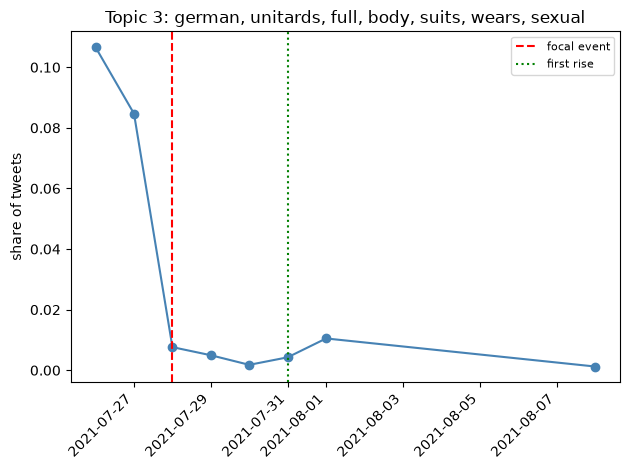

In [75]:
change_days = {} # Find the first day each consumer topic goes up

for topic_number in consumer_topics:
    shares = share_table[topic_number]
    change_day = None

    for i in range(1, len(shares)):
        if shares.iloc[i] > shares.iloc[i - 1]:
            change_day = shares.index[i]
            break

    change_days[topic_number] = change_day
    print(f"Topic {topic_number}: first rise on {change_day}")

    # Plot it
    plt.plot(pd.to_datetime(list(shares.index)), shares.values, "o-", color="steelblue")
    plt.axvline(FDATE, color="red", linestyle="--", label="focal event")
    if change_day is not None:
        plt.axvline(pd.Timestamp(change_day), color="green", linestyle=":", label="first rise")
    plt.title(f"Topic {topic_number}: {topic_words[topic_number][:50]}")
    plt.ylabel("share of tweets")
    plt.xticks(rotation=45, ha="right")
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

Topic 3: searching Google Trends for 'unitards'


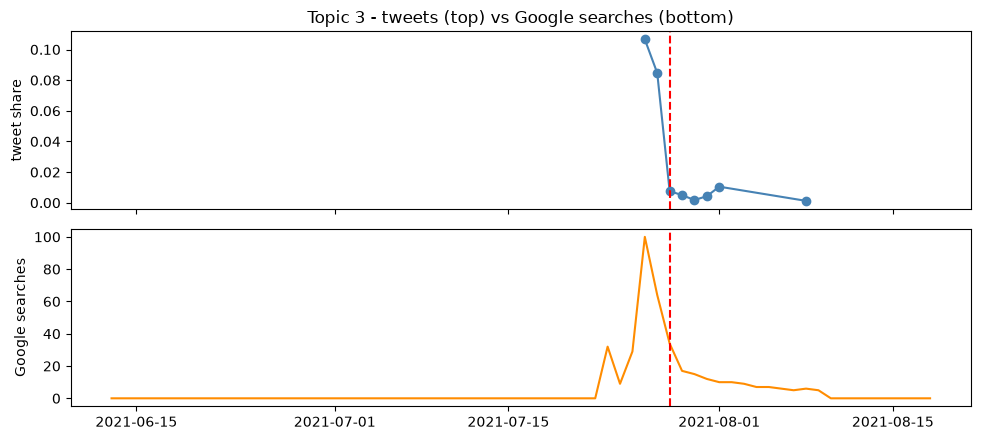

In [74]:
def get_trends(term):
    start = FDATE - timedelta(days=45)     # we look back so we know the normal level
    end = FDATE + timedelta(days=21)

    connection = TrendReq(hl="en-US", tz=0)
    connection.build_payload([term], timeframe=f"{start.date()} {end.date()}")
    result = connection.interest_over_time()

    if len(result) == 0:
        return None
    if "isPartial" in result.columns:
        result = result[result["isPartial"] == False]

    time.sleep(2)          # do not hammer the server
    return result[term]

lead_times = [] # Pick a search word for each consumer topic from its own top words

for topic_number in consumer_topics:
    words = [w.strip() for w in topic_words[topic_number].split(",")]
    search_term = words[0]
    for w in words:
        if has_word(w, consumer_words):
            search_term = w
            break

    print(f"Topic {topic_number}: searching Google Trends for '{search_term}'")

    try:
        series = get_trends(search_term)
    except Exception as e:
        print("   could not get data:", type(e).__name__)
        continue

    if series is None:
        print("   Google Trends had no data for this word")
        continue

    normal = series[series.index < FDATE] # Finding the first day searches go clearly above the normal level
    threshold = normal.mean() + 1.5 * normal.std()
    after = series[series.index >= FDATE - timedelta(days=7)]

    trends_day = None
    for day, value in after.items():
        if value > threshold:
            trends_day = day.date()
            break

    tweet_day = change_days[topic_number]

    if tweet_day is not None and trends_day is not None:
        lead = (pd.Timestamp(trends_day) - pd.Timestamp(tweet_day)).days
    else:
        lead = None

    lead_times.append({
        "topic": topic_number,
        "search term": search_term,
        "tweets rose": tweet_day,
        "searches rose": trends_day,
        "lead time (days)": lead,
    })

    # Plot both together
    fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)
    s = share_table[topic_number]
    top.plot(pd.to_datetime(list(s.index)), s.values, "o-", color="steelblue")
    top.set_ylabel("tweet share")
    bottom.plot(series.index, series.values, color="darkorange")
    bottom.set_ylabel("Google searches")
    for ax in [top, bottom]:
        ax.axvline(FDATE, color="red", linestyle="--")
    top.set_title(f"Topic {topic_number} - tweets (top) vs Google searches (bottom)")
    plt.tight_layout()
    plt.show()

---
### Our answers

In [73]:
print("=" * 68)
print("RQ2 - Which consumer interest topics appeared?")
print("=" * 68)
print("BERTopic found", len(topic_words), "topics in", len(data), "gymnastics tweets.")
print("Of these,", len(consumer_topics), "were about consumer interest.")
for t in consumer_topics:
    print(f"   Topic {t}: {topic_words[t][:60]}")
print("=" * 68)
print("RQ3 - Did Google Trends change too?")
print("=" * 68)

if len(lead_times) > 0:
    answers = pd.DataFrame(lead_times)
    display(answers)
    matched = answers["searches rose"].notna().sum()
    print(f"{matched} of {len(answers)} topics also changed in Google Trends.")
else:
    print("We could not get Google Trends data.")

print("=" * 68)
print("RQ1 - Did the tweets change first, and by how many days?")
print("=" * 68)

if len(lead_times) > 0:
    answers = pd.DataFrame(lead_times)
    have_both = answers[answers["lead time (days)"].notna()]
    if len(have_both) > 0:
        for _, row in have_both.iterrows():
            days = row["lead time (days)"]
            if days > 0:
                print(f"   Topic {row['topic']}: tweets changed {days} days FIRST")
            elif days < 0:
                print(f"   Topic {row['topic']}: searches changed {-days} days first")
            else:
                print(f"   Topic {row['topic']}: both changed on the same day")
    else:
        print("   We do not have both dates for any topic, so we cannot")
        print("   work out a lead time. We report this rather than guess.")
else:
    print("   Not enough data to answer.")

RQ2 - Which consumer interest topics appeared?
BERTopic found 27 topics in 11257 gymnastics tweets.
Of these, 1 were about consumer interest.
   Topic 3: german, unitards, full, body, suits, wears, sexualization, g
RQ3 - Did Google Trends change too?


,topic,search term,tweets rose,searches rose,lead time (days)
0,3,unitards,2021-07-31,2021-07-26,-5


1 of 1 topics also changed in Google Trends.
RQ1 - Did the tweets change first, and by how many days?
   Topic 3: searches changed 5 days first


---
### What we can and cannot say

**We can say** when things happened, and in which order.

**We cannot say** that the event caused anything. Two things happening in order does not prove
one caused the other — a news story could have caused both.

**We cannot say** anything about people actually buying things. Tweets and searches both measure
*attention*, not purchases.

**Our data is limited.** We only have 8 days, only 2 of them before the event, and the days
before the event are dominated by the Simone Biles story rather than being a quiet normal
baseline.